##This is a quality assessment of the Fire25 dataset from CalFire##

In [6]:
from pathlib import Path
import pandas as pd
import seaborn as sns

In [25]:
#Create raw folder path
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / "data" / "raw"

#Create raw csv file variables
fire25_csv = raw_fldr / "fire_25_TD.csv"

#Import csv as data frames
fire25_raw = pd.read_csv(fire25_csv,
                         parse_dates= ["ALARM_DATE","CONT_DATE"],
                         date_format="%m/%d/%Y %H:%M:%S")

In [4]:
#Finding Missing values

missing = fire25_raw.isna().sum().sort_values(ascending=False)

print(missing)

COMPLEX_ID      22750
COMPLEX_NAME    22716
COMMENTS        20372
IRWINID         19701
CONT_DATE       12618
FIRE_NAME        6655
FIRE_NUM         6136
ALARM_DATE       5384
INC_NUM           955
OBJECTIVE         271
d_OBJECTIVE       271
YEAR_              77
d_UNIT_ID          62
UNIT_ID            60
AGENCY             48
d_AGENCY           48
C_METHOD            0
STATE               0
Shape_Length        0
GIS_ACRES           0
CAUSE               0
Shape_Area          0
d_STATE             0
GlobalID            0
d_C_METHOD          0
d_CAUSE             0
dtype: int64


This was promising for the analysis that we want to do because many of the variable that we wanted to analyze have very low null values, like cause and agency. The most important variable that is missing a lot of data is CONT_DATE or containment date, as the differnce between containment date and start date is how we are planning on calculating the duration of the fire, so missing that will make that analysis more limited. There are still ~10,000 fires that have both, so that sample size should still be good, but the later step of showing the distribution over time of the null values will give a better idea of how important that is.

In [26]:
#Cleaning the data to look at years
fire25 = fire25_raw.loc[:,['YEAR_', 'd_AGENCY', 'd_UNIT_ID', 'FIRE_NAME', 'INC_NUM', 'ALARM_DATE', 'CONT_DATE', 'GIS_ACRES', 'd_CAUSE', 'd_C_METHOD', 'd_OBJECTIVE', 'COMMENTS']]

fire25 = fire25.rename(
    columns={
        'YEAR_': 'YEAR',
        'd_AGENCY': 'AGENCY',
        'd_UNIT_ID': 'UNIT_ID',
        'd_CAUSE': 'CAUSE',
        'd_OBJECTIVE': 'OBJECTIVE',
        'd_C_METHOD': 'C_METHOD'
    }
)
fire25.head()


,YEAR,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,ALARM_DATE,CONT_DATE,GIS_ACRES,CAUSE,C_METHOD,OBJECTIVE,COMMENTS
0,2025.0,USDA Forest Service,Los Padres National Forest,GIFFORD,00002181,2025-08-01,2025-10-14,131613.531250,Unknown / Unidentified,Infrared,Suppression (Wildfire),NaN
1,2025.0,USDA Forest Service,Los Padres National Forest,MADRE,00001817,2025-07-02,2025-07-26,80779.101562,Unknown / Unidentified,Mixed Collection Methods,Suppression (Wildfire),NaN
2,2025.0,USDA Forest Service,Sierra National Forest,GARNET,00001684,2025-08-24,2025-10-23,60019.234375,Lightning,Infrared,Suppression (Wildfire),NaN
3,2025.0,California Department of Forestry and Fire Pro...,Fresno-Kings CAL FIRE,SALT,00018739,2025-09-02,2025-09-17,25553.546875,Lightning,Mixed Collection Methods,Suppression (Wildfire),Park incident clipped out per BEU
4,2025.0,California Department of Forestry and Fire Pro...,Los Angeles City FD,PALISADES,00000738,2025-01-07,2025-01-31,23448.882812,Unknown / Unidentified,Mixed Collection Methods,Suppression (Wildfire),NaN


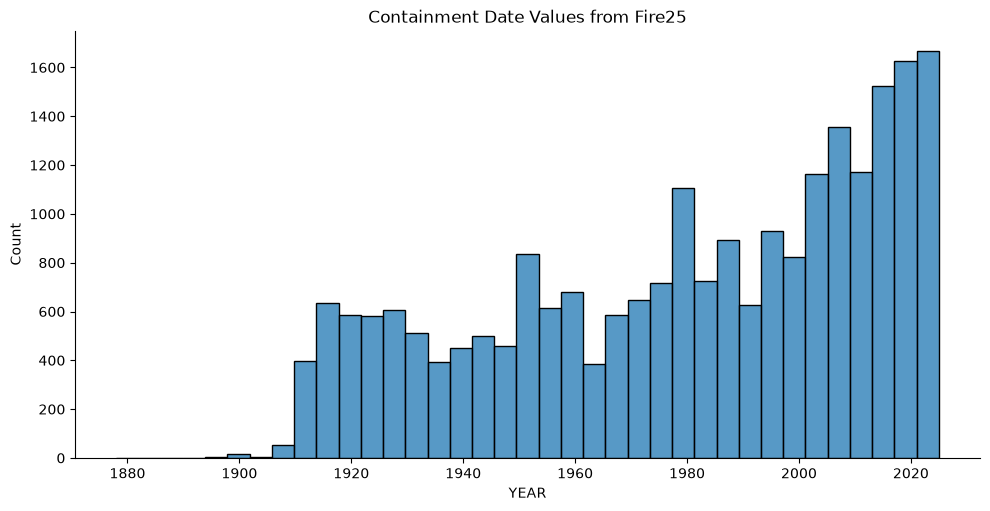

In [32]:
sns.displot(data = fire25,
            x = 'YEAR',
            aspect = 2
            ).set(title = "Containment Date Values from Fire25");

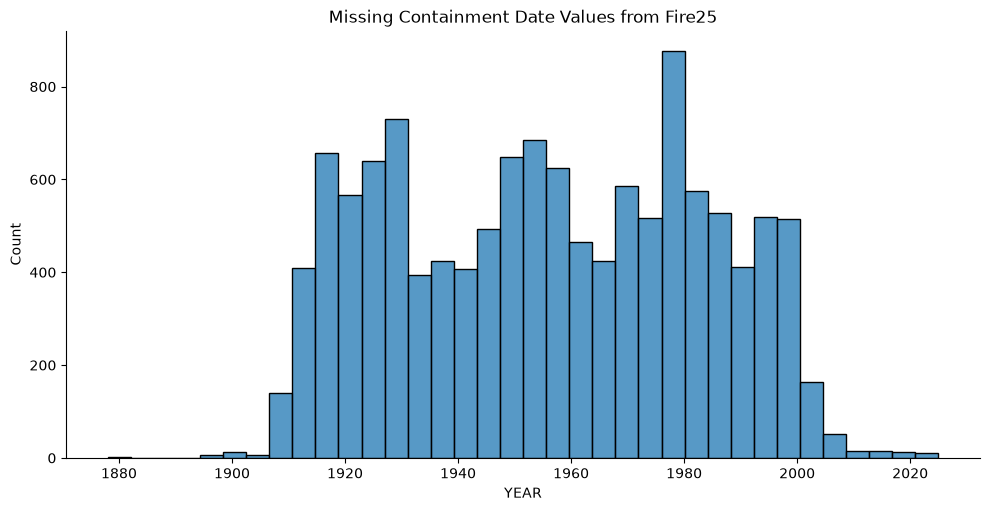

In [31]:
sns.displot(data = fire25.loc[fire25['CONT_DATE'].isna()],
            x = 'YEAR',
            aspect = 2
            ).set(title = "Missing Containment Date Values from Fire25");

So from these two figures, it seems like there are a lot of missing containment date values before the year 2000 with a large decrease in the missing values after then. This also lines up with with an increase in data which is either from more fires or better data collection starting around the year 2000, so we decided to start our analysis with the years after 2000.

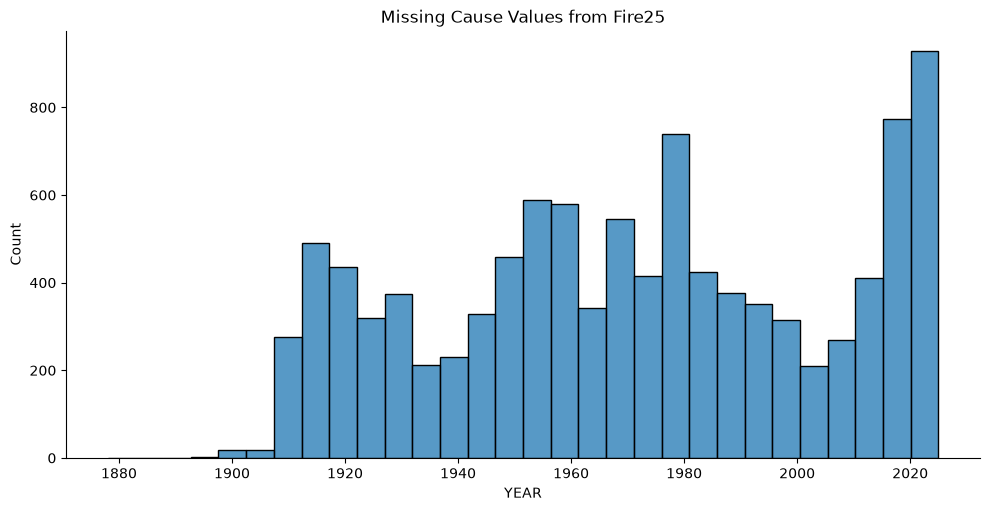

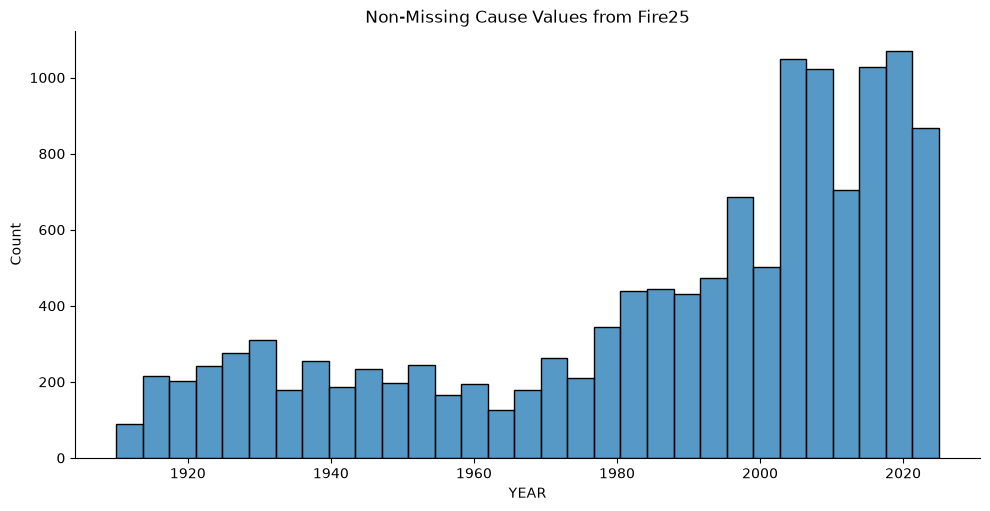

In [ ]:
#Looking at known causes of fire
cause = fire25.loc[fire25['CAUSE'] == 'Unknown / Unidentified']

sns.displot(data = fire25.loc[fire25['CAUSE'] == 'Unknown / Unidentified'],
            x = 'YEAR',
            aspect = 2
            ).set(title = "Missing Cause Values from Fire25");

sns.displot(data = fire25.loc[fire25['CAUSE'] != 'Unknown / Unidentified'],
            x = 'YEAR',
            aspect = 2
            ).set(title = "Non-Missing Cause Values from Fire25");


This is a similar set of figures to the ones above, but for cause, since unknow causes are still recored and will not show up wiht the isna analysis. It looks like we will be working with less data for the known cause analysis that we are interested in, but once again it will still be a solid sample, we will just have to note the difference in sample sizes. 